In [1]:
from z2chain.exact import sparse_hamiltonian
import matplotlib.pyplot as plt
import scipy.sparse as sparse
import numpy as np

In [2]:
L = 5

lamb = 1
points = 101

gvals = np.linspace(0, 2, points)
gap_values = np.zeros_like(gvals)
E_gs = np.zeros_like(gvals)
for i, g in enumerate(gvals):
    H = sparse_hamiltonian(0, g, lamb, L).toarray()
    evals, evecs = np.linalg.eigh(H)
    E_gs[i] = evals[0]
    unique_evals = np.unique(np.round(evals, 8))
    gap_values[i] = unique_evals[1] - unique_evals[0]

In [25]:
def gap_function(lamb, g):
    angle = np.atan(lamb/g)/2
    return 2*lamb*np.sin(2*angle) + 2*g*np.cos(2*angle)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_6663/2977109157.py:2: RuntimeWarning: divide by zero encountered in scalar divide
  angle = np.atan(lamb/g)/2


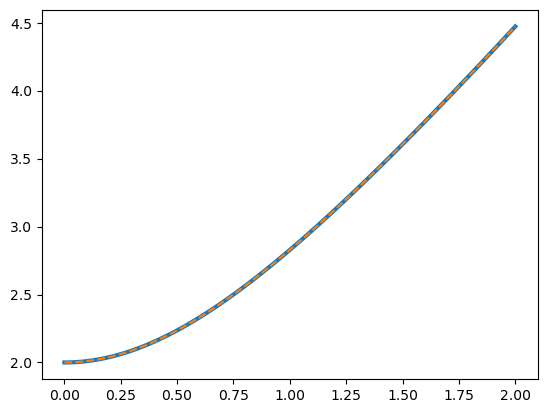

In [27]:
plt.plot(gvals, gap_values, linewidth=3)
plt.plot(gvals, [gap_function(lamb, g) for g in gvals], '--')

In [ ]:
def var_egs(lamb, g):
    angle = np.atan(lamb/g)/2
    return -lamb * np.sin(2*angle) - g * np.cos(2*angle)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_6663/3988261638.py:2: RuntimeWarning: divide by zero encountered in scalar divide
  angle = np.atan(lamb/g)/2


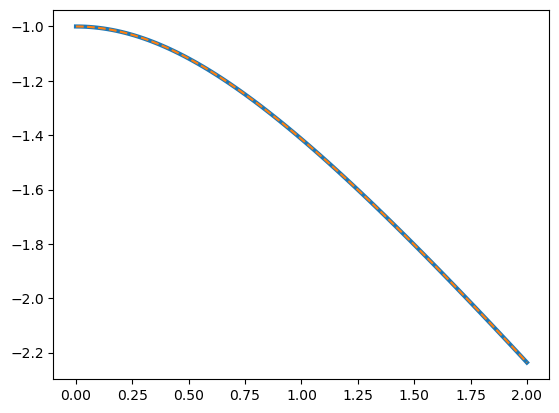

In [22]:
plt.plot(gvals, E_gs/(L-1), linewidth=3)
plt.plot(gvals, [var_egs(lamb, g) for g in gvals], '--')